## **G2_Baseline Verification and Feasibility**

**QASPER dataset loading and split verification**



In [33]:

import requests
from datasets import load_dataset

api_url = "https://datasets-server.huggingface.co/parquet"
response = requests.get(
    api_url,
    params={"dataset": "allenai/qasper"},
    timeout=60
)
response.raise_for_status()

parquet_info = response.json()

print("Available Parquet files:")
for file in parquet_info["parquet_files"]:
    print(file["split"], file["url"])

data_files = {}
for file in parquet_info["parquet_files"]:
    split = file["split"]
    data_files.setdefault(split, []).append(file["url"])

dataset = load_dataset("parquet", data_files=data_files)

print("\nLoaded dataset:")
print(dataset)

for split in dataset:
    papers = dataset[split]
    question_count = sum(
        len(paper["qas"]["question"])
        for paper in papers
    )
    print(f"\nSplit: {split}")
    print("Number of papers:", len(papers))
    print("Number of questions:", question_count)

sample = dataset["train"][0]

print("\nSample paper:", sample["title"])
print("Number of sections:", len(sample["full_text"]["section_name"]))
print("First two questions:", sample["qas"]["question"][:2])
print("Answer annotation keys:", sample["qas"]["answers"][0].keys())


Available Parquet files:
test https://huggingface.co/datasets/allenai/qasper/resolve/refs%2Fconvert%2Fparquet/qasper/test/0000.parquet
train https://huggingface.co/datasets/allenai/qasper/resolve/refs%2Fconvert%2Fparquet/qasper/train/0000.parquet
validation https://huggingface.co/datasets/allenai/qasper/resolve/refs%2Fconvert%2Fparquet/qasper/validation/0000.parquet

Loaded dataset:
DatasetDict({
    test: Dataset({
        features: ['id', 'title', 'abstract', 'full_text', 'qas', 'figures_and_tables'],
        num_rows: 416
    })
    train: Dataset({
        features: ['id', 'title', 'abstract', 'full_text', 'qas', 'figures_and_tables'],
        num_rows: 888
    })
    validation: Dataset({
        features: ['id', 'title', 'abstract', 'full_text', 'qas', 'figures_and_tables'],
        num_rows: 281
    })
})

Split: test
Number of papers: 416
Number of questions: 1451

Split: train
Number of papers: 888
Number of questions: 2593

Split: validation
Number of papers: 281
Number of qu

 **Answer and evidence schema inspection**

In [34]:
import json

sample = dataset["train"][0]

print("QUESTION:")
print(sample["qas"]["question"][0])

print("\nQA STRUCTURE:")
print(sample["qas"].keys())

print("\nANSWER ANNOTATION:")
print(json.dumps(
    sample["qas"]["answers"][0],
    indent=2
)[:5000])

print("\nFULL TEXT STRUCTURE:")
print(sample["full_text"].keys())

print("\nFIRST SECTION:")
print(sample["full_text"]["section_name"][0])

print("\nFIRST SECTION PARAGRAPHS:")
print(json.dumps(
    sample["full_text"]["paragraphs"][0],
    indent=2
)[:2000])

QUESTION:
What is the seed lexicon?

QA STRUCTURE:
dict_keys(['question', 'question_id', 'nlp_background', 'topic_background', 'paper_read', 'search_query', 'question_writer', 'answers'])

ANSWER ANNOTATION:
{
  "answer": [
    {
      "unanswerable": false,
      "extractive_spans": [],
      "yes_no": null,
      "free_form_answer": "a vocabulary of positive and negative predicates that helps determine the polarity score of an event",
      "evidence": [
        "The seed lexicon consists of positive and negative predicates. If the predicate of an extracted event is in the seed lexicon and does not involve complex phenomena like negation, we assign the corresponding polarity score ($+1$ for positive events and $-1$ for negative events) to the event. We expect the model to automatically learn complex phenomena through label propagation. Based on the availability of scores and the types of discourse relations, we classify the extracted event pairs into the following three types."
     

In [35]:
from collections import Counter

answer_types = Counter()
unanswerable_count = 0
evidence_count = 0
total_annotations = 0

for paper in dataset["train"]:
    for answers in paper["qas"]["answers"]:
        for annotation in answers["answer"]:
            total_annotations += 1

            if annotation["unanswerable"]:
                answer_types["unanswerable"] += 1
                unanswerable_count += 1

            elif annotation["extractive_spans"]:
                answer_types["extractive"] += 1

            elif annotation["yes_no"] is not None:
                answer_types["yes_no"] += 1

            elif annotation["free_form_answer"].strip():
                answer_types["free_form"] += 1

            else:
                answer_types["other_or_empty"] += 1

            if annotation["evidence"]:
                evidence_count += 1

print("Total annotations:", total_annotations)
print("\nAnswer type distribution:")
for answer_type, count in answer_types.items():
    print(answer_type, ":", count)

print("\nAnnotations with evidence:", evidence_count)
print(
    "Evidence availability:",
    round(evidence_count / total_annotations * 100, 2),
    "%"
)

Total annotations: 2675

Answer type distribution:
free_form : 622
extractive : 1363
yes_no : 409
unanswerable : 281

Annotations with evidence: 2308
Evidence availability: 86.28 %


In [36]:
sample = dataset["train"][0]

print("Paper:", sample["title"])

for section_idx, (section, paragraphs) in enumerate(
    zip(
        sample["full_text"]["section_name"],
        sample["full_text"]["paragraphs"]
    )
):
    print(f"\nSection {section_idx}: {section}")
    print("Number of paragraphs:", len(paragraphs))

    for paragraph_idx, paragraph in enumerate(paragraphs[:2]):
        print(f"Paragraph {paragraph_idx}:")
        print(paragraph[:400])

Paper: Minimally Supervised Learning of Affective Events Using Discourse Relations

Section 0: Introduction
Number of paragraphs: 4
Paragraph 0:
Affective events BIBREF0 are events that typically affect people in positive or negative ways. For example, getting money and playing sports are usually positive to the experiencers; catching cold and losing one's wallet are negative. Understanding affective events is important to various natural language processing (NLP) applications such as dialogue systems BIBREF1, question-answering systems BI
Paragraph 1:
Learning affective events is challenging because, as the examples above suggest, the polarity of an event is not necessarily predictable from its constituent words. Combined with the unbounded combinatorial nature of language, the non-compositionality of affective polarity entails the need for large amounts of world knowledge, which can hardly be learned from small annotated data.

Section 1: Related Work
Number of paragraphs: 5
Paragrap

In [37]:
import re

def normalize(text):
    return re.sub(r"\s+", " ", text).strip().lower()

sample = dataset["train"][0]

passages = []

for section_idx, (section, paragraphs) in enumerate(
    zip(
        sample["full_text"]["section_name"],
        sample["full_text"]["paragraphs"]
    )
):
    for paragraph_idx, paragraph in enumerate(paragraphs):
        if paragraph.strip():
            passages.append({
                "passage_id": f"S{section_idx}_P{paragraph_idx}",
                "section": section,
                "text": paragraph
            })

print("Total non-empty passages:", len(passages))

question_idx = 0
print("\nQuestion:", sample["qas"]["question"][question_idx])

for annotation_idx, annotation in enumerate(
    sample["qas"]["answers"][question_idx]["answer"]
):
    print(f"\nAnnotation {annotation_idx + 1}")

    for evidence in annotation["evidence"]:
        normalized_evidence = normalize(evidence)

        matches = [
            passage["passage_id"]
            for passage in passages
            if normalized_evidence in normalize(passage["text"])
        ]

        print("Evidence:", evidence[:250])
        print("Matching passage IDs:", matches)

Total non-empty passages: 56

Question: What is the seed lexicon?

Annotation 1
Evidence: The seed lexicon consists of positive and negative predicates. If the predicate of an extracted event is in the seed lexicon and does not involve complex phenomena like negation, we assign the corresponding polarity score ($+1$ for positive events an
Matching passage IDs: ['S4_P1']

Annotation 2
Evidence: The seed lexicon consists of positive and negative predicates. If the predicate of an extracted event is in the seed lexicon and does not involve complex phenomena like negation, we assign the corresponding polarity score ($+1$ for positive events an
Matching passage IDs: ['S4_P1']


**Training evidence mapping validation**

In [38]:
import re

def normalize(text):
    return re.sub(r"\s+", " ", text).strip().lower()

total_evidence = 0
matched_evidence = 0
unmatched_evidence = 0
annotations_with_evidence = 0
annotations_with_match = 0

for paper in dataset["train"]:

    paragraphs = []

    for section_idx, section_paragraphs in enumerate(
        paper["full_text"]["paragraphs"]
    ):
        for paragraph_idx, paragraph in enumerate(section_paragraphs):
            if paragraph.strip():
                paragraphs.append(normalize(paragraph))

    for qa in paper["qas"]["answers"]:
        for annotation in qa["answer"]:

            evidence_list = annotation["evidence"]

            if not evidence_list:
                continue

            annotations_with_evidence += 1
            annotation_matched = False

            for evidence in evidence_list:
                total_evidence += 1
                normalized_evidence = normalize(evidence)

                found = any(
                    normalized_evidence in paragraph
                    for paragraph in paragraphs
                )

                if found:
                    matched_evidence += 1
                    annotation_matched = True
                else:
                    unmatched_evidence += 1

            if annotation_matched:
                annotations_with_match += 1

print("Total evidence statements:", total_evidence)
print("Matched evidence statements:", matched_evidence)
print("Unmatched evidence statements:", unmatched_evidence)

print(
    "Evidence statement matching rate:",
    round(matched_evidence / total_evidence * 100, 2)
)

print("Annotations containing evidence:", annotations_with_evidence)
print("Annotations with at least one matched statement:", annotations_with_match)

print(
    "Annotation-level matching rate:",
    round(annotations_with_match / annotations_with_evidence * 100, 2)
)

Total evidence statements: 4209
Matched evidence statements: 3691
Unmatched evidence statements: 518
Evidence statement matching rate: 87.69
Annotations containing evidence: 2308
Annotations with at least one matched statement: 2161
Annotation-level matching rate: 93.63


**CPU environment verification**

In [39]:
import torch
import psutil

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("RAM available (GB):", round(
    psutil.virtual_memory().available / (1024**3), 2
))

PyTorch: 2.14.1+cpu
CUDA available: False
RAM available (GB): 9.39


**BM25 validation-split execution**

In [40]:
!pip -q install rank_bm25

import re
import numpy as np
from rank_bm25 import BM25Okapi

def normalize(text):
    return re.sub(r"\s+", " ", text).strip().lower()

def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

results = []
skipped = 0

for paper in dataset["validation"]:

    passages = []

    for section_idx, (section, paragraphs) in enumerate(
        zip(
            paper["full_text"]["section_name"],
            paper["full_text"]["paragraphs"]
        )
    ):
        for paragraph_idx, paragraph in enumerate(paragraphs):

            if paragraph.strip():
                passages.append({
                    "id": f"S{section_idx}_P{paragraph_idx}",
                    "text": paragraph
                })

    if not passages:
        continue

    tokenized_corpus = [
        tokenize(passage["text"])
        for passage in passages
    ]

    bm25 = BM25Okapi(tokenized_corpus)

    for question, answer_group in zip(
        paper["qas"]["question"],
        paper["qas"]["answers"]
    ):

        gold_ids = set()

        for annotation in answer_group["answer"]:
            for evidence in annotation["evidence"]:

                normalized_evidence = normalize(evidence)

                for passage in passages:
                    if normalized_evidence in normalize(passage["text"]):
                        gold_ids.add(passage["id"])

        if not gold_ids:
            skipped += 1
            continue

        scores = bm25.get_scores(tokenize(question))
        top_indices = np.argsort(scores)[::-1][:5]

        ranked_ids = [
            passages[i]["id"]
            for i in top_indices
        ]

        results.append({
            "question": question,
            "gold_ids": gold_ids,
            "ranked_ids": ranked_ids
        })

def recall_at_k(results, k):
    return np.mean([
        bool(set(item["ranked_ids"][:k]) & item["gold_ids"])
        for item in results
    ])

def mrr_at_k(results, k):
    reciprocal_ranks = []

    for item in results:
        rank = next(
            (
                i + 1
                for i, pid in enumerate(item["ranked_ids"][:k])
                if pid in item["gold_ids"]
            ),
            None
        )

        reciprocal_ranks.append(
            1 / rank if rank else 0
        )

    return np.mean(reciprocal_ranks)

print("Evaluated questions:", len(results))
print("Skipped questions without mapped evidence:", skipped)

for k in [1, 3, 5]:
    print(f"Recall@{k}: {recall_at_k(results, k):.4f}")

print("MRR@5:", round(mrr_at_k(results, 5), 4))

Evaluated questions: 888
Skipped questions without mapped evidence: 117
Recall@1: 0.2106
Recall@3: 0.4392
Recall@5: 0.6014
MRR@5: 0.3457


**Retrieval result inspection**

In [41]:
for paper in list(dataset["validation"])[:5]:

    passages = []

    for section_idx, (section, paragraphs) in enumerate(
        zip(
            paper["full_text"]["section_name"],
            paper["full_text"]["paragraphs"]
        )
    ):
        for paragraph_idx, paragraph in enumerate(paragraphs):
            if paragraph.strip():
                passages.append({
                    "id": f"S{section_idx}_P{paragraph_idx}",
                    "section": section,
                    "text": paragraph
                })

    if not passages:
        continue

    bm25 = BM25Okapi([
        tokenize(p["text"]) for p in passages
    ])

    for question, answer_group in zip(
        paper["qas"]["question"],
        paper["qas"]["answers"]
    ):

        gold_ids = set()

        for annotation in answer_group["answer"]:
            for evidence in annotation["evidence"]:
                ev = normalize(evidence)

                for p in passages:
                    if ev in normalize(p["text"]):
                        gold_ids.add(p["id"])

        if not gold_ids:
            continue

        scores = bm25.get_scores(tokenize(question))
        top_indices = np.argsort(scores)[::-1][:5]

        print("\nQUESTION:", question)
        print("GOLD:", gold_ids)

        for rank, idx in enumerate(top_indices, 1):
            p = passages[idx]
            print(
                f"\nRank {rank} | {p['id']} | "
                f"Gold: {p['id'] in gold_ids}"
            )
            print(p["text"][:350])

        break


QUESTION: which multilingual approaches do they compare with?
GOLD: {'S9_P0'}

Rank 1 | S9_P0 | Gold: True
Table TABREF19 and TABREF26 report zero-shot results on Europarl and Multi-UN evaluation sets, respectively. We compare our approaches with related approaches of pivoting, multilingual NMT (MNMT) BIBREF19, and cross-lingual transfer without pretraining BIBREF16. The results show that our approaches consistently outperform other approaches across la

Rank 2 | S0_P6 | Gold: False
Our proposed approach significantly improves zero-shot translation performance, consistently surpassing pivoting and multilingual approaches. Meanwhile, the performance on supervised translation direction remains the same level or even better when using our method.

Rank 3 | S15_P0 | Gold: False
In this paper, we propose a cross-lingual pretraining based transfer approach for the challenging zero-shot translation task, in which source and target languages have no parallel data, while they both have paralle

In [42]:
!pip -q install transformers sentencepiece

import torch
import time
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google/flan-t5-small"

start = time.perf_counter()

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

model.eval()

model_load_time = time.perf_counter() - start

print("Model:", model_name)
print("Device: CPU")
print("Model loading time:", round(model_load_time, 2), "seconds")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Model: google/flan-t5-small
Device: CPU
Model loading time: 1.67 seconds


**Lightweight language model inference test**

In [43]:
import time
import numpy as np

paper = dataset["validation"][0]

passages = []

for section_idx, (section, paragraphs) in enumerate(
    zip(
        paper["full_text"]["section_name"],
        paper["full_text"]["paragraphs"]
    )
):
    for paragraph_idx, paragraph in enumerate(paragraphs):
        if paragraph.strip():
            passages.append({
                "id": f"S{section_idx}_P{paragraph_idx}",
                "text": paragraph
            })

bm25 = BM25Okapi([
    tokenize(p["text"]) for p in passages
])

question = paper["qas"]["question"][0]

scores = bm25.get_scores(tokenize(question))
top_indices = np.argsort(scores)[::-1][:5]

retrieved = [passages[i] for i in top_indices]

context = "\n\n".join(
    f"[{p['id']}] {p['text']}"
    for p in retrieved
)

prompt = f"""
Answer the question using only the provided scientific paper passages.

Question: {question}

Passages:
{context}

Give a concise answer. If the passages do not contain the answer,
say that the information is insufficient.
"""

inputs = tokenizer(
    prompt,
    return_tensors="pt",
    truncation=True,
    max_length=512
)

start = time.perf_counter()

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=False
    )

inference_time = time.perf_counter() - start

answer = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("Paper:", paper["title"])
print("Question:", question)

print("\nRetrieved passages:")
for p in retrieved:
    print(p["id"], ":", p["text"][:250])

print("\nGenerated answer:", answer)
print("Inference time:", round(inference_time, 2), "seconds")

Paper: Cross-lingual Pre-training Based Transfer for Zero-shot Neural Machine Translation
Question: which multilingual approaches do they compare with?

Retrieved passages:
S9_P0 : Table TABREF19 and TABREF26 report zero-shot results on Europarl and Multi-UN evaluation sets, respectively. We compare our approaches with related approaches of pivoting, multilingual NMT (MNMT) BIBREF19, and cross-lingual transfer without pretraini
S0_P6 : Our proposed approach significantly improves zero-shot translation performance, consistently surpassing pivoting and multilingual approaches. Meanwhile, the performance on supervised translation direction remains the same level or even better when us
S15_P0 : In this paper, we propose a cross-lingual pretraining based transfer approach for the challenging zero-shot translation task, in which source and target languages have no parallel data, while they both have parallel data with a high resource pivot la
S7_P1 : For MultiUN corpus, we use four languages

**End-to-end QA validation**

In [44]:
prompt = f"""You are answering a question about a scientific research paper.

Answer the question using only the information explicitly stated in the passages below.

Do not output bibliography identifiers such as BIBREF19.
Explain the actual method or approach names in ordinary words.
If the answer is not clearly available, say "Insufficient information".

Question:
{question}

Scientific passages:
{context}

Answer:"""

inputs = tokenizer(
    prompt,
    return_tensors="pt",
    truncation=True,
    max_length=512
)

start = time.perf_counter()

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=False
    )

inference_time = time.perf_counter() - start

answer = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("Question:", question)
print("Generated answer:", answer)
print("Inference time:", round(inference_time, 2), "seconds")

Question: which multilingual approaches do they compare with?
Generated answer: pivoting, multilingual NMT (MNMT) BIBREF19, and cross-lingual transfer without pretraining
Inference time: 1.01 seconds


In [45]:

import time
import pandas as pd
import numpy as np
from rank_bm25 import BM25Okapi
import torch

results = []

for paper_idx in range(5):
    paper = dataset["validation"][paper_idx]
    passages = []

    for si, (section, paragraphs) in enumerate(zip(
        paper["full_text"]["section_name"],
        paper["full_text"]["paragraphs"]
    )):
        for pi, paragraph in enumerate(paragraphs):
            if paragraph.strip():
                passages.append({
                    "id": f"S{si}_P{pi}",
                    "text": paragraph
                })

    if not passages or not paper["qas"]["question"]:
        continue

    question = paper["qas"]["question"][0]

    bm25 = BM25Okapi([tokenize(p["text"]) for p in passages])
    scores = bm25.get_scores(tokenize(question))
    top_indices = np.argsort(scores)[::-1][:5]
    retrieved = [passages[i] for i in top_indices]

    context = "\n\n".join(
        f"[{p['id']}] {p['text']}" for p in retrieved
    )

    prompt = f"""Answer the question using only the scientific passages.
Do not output bibliography identifiers.
Explain the answer in ordinary words.
If the answer is unavailable, say insufficient information.

Question: {question}

Passages:
{context}

Answer:"""

    inputs = tokenizer(
        prompt, return_tensors="pt",
        truncation=True, max_length=512
    )

    start = time.perf_counter()

    with torch.no_grad():
        outputs = model.generate(
            **inputs, max_new_tokens=100, do_sample=False
        )

    elapsed = time.perf_counter() - start
    answer = tokenizer.decode(outputs[0], skip_special_tokens=True)

    results.append({
        "paper_id": paper["id"],
        "paper_title": paper["title"],
        "question": question,
        "retrieved_passage_ids": ", ".join(p["id"] for p in retrieved),
        "generated_answer": answer,
        "inference_time_seconds": round(elapsed, 2)
    })

    print(f"\nPaper {paper_idx + 1}: {paper['title']}")
    print("Question:", question)
    print("Answer:", answer)
    print("Inference time:", round(elapsed, 2), "seconds")

pd.DataFrame(results).to_csv("g2_baseline_pilot.csv", index=False)
print("\nSaved g2_baseline_pilot.csv")
print("Questions tested:", len(results))



Paper 1: Cross-lingual Pre-training Based Transfer for Zero-shot Neural Machine Translation
Question: which multilingual approaches do they compare with?
Answer: pivoting, multilingual NMT (MNMT) BIBREF19, and cross-lingual transfer without pretraining BIBREF16
Inference time: 1.1 seconds

Paper 2: pioNER: Datasets and Baselines for Armenian Named Entity Recognition
Question: what ner models were evaluated?
Answer: NER, spaCy 2.0, and a recurrent model similar to BIBREF13 , BIBREF14
Inference time: 1.04 seconds

Paper 3: Identifying Dogmatism in Social Media: Signals and Models
Question: what are the topics pulled from Reddit?
Answer: R1: What kinds of topics (e.g., guns, LGBT) attract the highest levels of dogmatism?
Inference time: 1.01 seconds

Paper 4: Adversarial Learning for Chinese NER from Crowd Annotations
Question: What accuracy does the proposed system achieve?
Answer: Identifier the types of entities.
Inference time: 0.58 seconds

Paper 5: Addressing word-order Divergence 

## **G3_Experimental Evidence**

**# G3.2B — Select Held-Out Test Questions (Corrected QASPER Schema)**

In [46]:

# G3.2B — Select Held-Out Test Questions (Corrected QASPER Schema)

import random
import re
import pandas as pd

def normalize_text(text):
    return re.sub(r"\s+", " ", str(text)).strip().lower()

candidates = []

for paper in dataset["test"]:
    paragraphs = []

    for si, section_paragraphs in enumerate(paper["full_text"]["paragraphs"]):
        for pi, paragraph in enumerate(section_paragraphs):
            if paragraph and paragraph.strip():
                paragraphs.append({
                    "id": f"S{si}_P{pi}",
                    "text": paragraph
                })

    qas = paper["qas"]

    for qi, question in enumerate(qas["question"]):
        gold_ids = set()
        references = []
        answer_types = set()

        answer_entry = qas["answers"][qi]
        annotations = answer_entry["answer"]

        for ann in annotations:
            if ann.get("unanswerable", False):
                continue

            yes_no = ann.get("yes_no")
            spans = ann.get("extractive_spans") or []
            free_form = ann.get("free_form_answer") or ""

            if yes_no is not None:
                answer_types.add("yes_no")
                references.append(str(yes_no))

            if spans:
                answer_types.add("extractive")
                references.extend(str(x) for x in spans if x)

            if free_form.strip():
                answer_types.add("free_form")
                references.append(free_form.strip())

            evidence = ann.get("evidence") or []

            if isinstance(evidence, str):
                evidence = [evidence]

            for ev in evidence:
                ev_norm = normalize_text(ev)

                if not ev_norm:
                    continue

                for p in paragraphs:
                    if ev_norm in normalize_text(p["text"]):
                        gold_ids.add(p["id"])

        if gold_ids and references:
            candidates.append({
                "paper_id": paper["id"],
                "paper_title": paper["title"],
                "question_id": qas["question_id"][qi],
                "question": question,
                "gold_evidence_ids": sorted(gold_ids),
                "reference_answers": list(set(references)),
                "answer_types": sorted(answer_types)
            })

random.seed(42)
random.shuffle(candidates)

sample = candidates[:50]

sample_df = pd.DataFrame(sample)
sample_df.to_json(
    "g3_test_sample.json",
    orient="records",
    indent=2
)

print("Eligible test questions:", len(candidates))
print("Selected questions:", len(sample_df))
print("\nAnswer-type distribution:")
print(sample_df["answer_types"].explode().value_counts())
print("\nSample preview:")
display(
    sample_df[
        ["paper_title", "question", "gold_evidence_ids"]
    ].head()
)

print("\nSaved g3_test_sample.json")


Eligible test questions: 1309
Selected questions: 50

Answer-type distribution:
answer_types
extractive    40
free_form     26
yes_no         7
Name: count, dtype: int64

Sample preview:


,paper_title,question,gold_evidence_ids
0,Detecting Offensive Language in Tweets Using D...,what results did their system obtain?,[S10_P0]
1,UIT-ViIC: A Dataset for the First Evaluation o...,What deep neural network models are used in ev...,"[S6_P0, S6_P1]"
2,"Location, Occupation, and Semantics based Soci...",How much data do they gather in total?,[S3_P0]
3,A Context-Aware Approach for Detecting Check-W...,What models are trained?,"[S0_P7, S8_P0]"
4,Common-Knowledge Concept Recognition for SEVA,What metrics are used for evaluation?,[S7_P1]



Saved g3_test_sample.json


In [47]:

# G3.3 — Build and Freeze BM25 Retrieval Results

import re
import json
import numpy as np
from rank_bm25 import BM25Okapi

def tokenize(text):
    return re.findall(r"\b\w+\b", str(text).lower())

paper_lookup = {
    paper["id"]: paper
    for paper in dataset["test"]
}

retrieval_records = []

for _, row in sample_df.iterrows():
    paper = paper_lookup[row["paper_id"]]

    passages = []

    for si, section_paragraphs in enumerate(paper["full_text"]["paragraphs"]):
        for pi, paragraph in enumerate(section_paragraphs):
            if paragraph and paragraph.strip():
                passages.append({
                    "id": f"S{si}_P{pi}",
                    "text": paragraph
                })

    corpus = [tokenize(p["text"]) for p in passages]
    bm25 = BM25Okapi(corpus)

    scores = bm25.get_scores(tokenize(row["question"]))
    top_indices = np.argsort(scores)[::-1][:5]

    retrieved = [
        passages[i] for i in top_indices
    ]

    retrieval_records.append({
        "paper_id": row["paper_id"],
        "question_id": row["question_id"],
        "question": row["question"],
        "gold_evidence_ids": row["gold_evidence_ids"],
        "reference_answers": row["reference_answers"],
        "answer_types": row["answer_types"],
        "retrieved_passages": retrieved
    })

with open("g3_frozen_retrieval.json", "w", encoding="utf-8") as f:
    json.dump(retrieval_records, f, ensure_ascii=False, indent=2)

hits_at_5 = sum(
    bool(set(r["gold_evidence_ids"]) &
         {p["id"] for p in r["retrieved_passages"]})
    for r in retrieval_records
)

print("Questions processed:", len(retrieval_records))
print("Questions with at least one gold passage in top 5:", hits_at_5)
print("Hit@5 on selected sample:", round(hits_at_5 / len(retrieval_records), 4))
print("Saved: g3_frozen_retrieval.json")

print("\nFirst retrieved example:")
print("Question:", retrieval_records[0]["question"])
print("Gold IDs:", retrieval_records[0]["gold_evidence_ids"])
print("Retrieved IDs:", [p["id"] for p in retrieval_records[0]["retrieved_passages"]])


Questions processed: 50
Questions with at least one gold passage in top 5: 29
Hit@5 on selected sample: 0.58
Saved: g3_frozen_retrieval.json

First retrieved example:
Question: what results did their system obtain?
Gold IDs: ['S10_P0']
Retrieved IDs: ['S7_P3', 'S2_P5', 'S10_P4', 'S0_P1', 'S10_P5']


**G3.4 — Generate Answers: Condition A (Answer-only)**

In [48]:

# G3.4 — Generate Answers: Condition A (Answer-only)

import json
import time
import torch

with open("g3_frozen_retrieval.json", "r", encoding="utf-8") as f:
    retrieval_records = json.load(f)

condition_a_results = []

for i, record in enumerate(retrieval_records):
    context = "\n\n".join(
        f"[{p['id']}] {p['text']}"
        for p in record["retrieved_passages"]
    )

    prompt = f"""Answer the question using only the scientific paper passages below.
Give a concise and direct answer.
Do not invent information.
If the answer is unavailable, say "Insufficient information".

Question: {record['question']}

Passages:
{context}

Answer:"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    start = time.perf_counter()

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False
        )

    elapsed = time.perf_counter() - start

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    condition_a_results.append({
        "paper_id": record["paper_id"],
        "question_id": record["question_id"],
        "question": record["question"],
        "answer": answer,
        "inference_time_seconds": round(elapsed, 3)
    })

    print(f"{i+1}/50 | {answer[:180]} | {elapsed:.2f}s")

with open("g3_condition_A.json", "w", encoding="utf-8") as f:
    json.dump(condition_a_results, f, ensure_ascii=False, indent=2)

print("\nCondition A completed:", len(condition_a_results))
print("Average inference time:",
      round(sum(x["inference_time_seconds"] for x in condition_a_results)
            / len(condition_a_results), 3), "seconds")
print("Saved: g3_condition_A.json")


1/50 | [S10_P3] The dense layer. The output of the LSTM was run through an additional layer to improve the learning and obtain more stable output. The ReLU activation function was used. I | 3.64s
2/50 | BLEU | 0.95s
3/50 | Insufficient information | 0.78s
4/50 | [S8_P1] | 0.90s
5/50 | [S2_P0] | 0.90s
6/50 | Network features have been shown to improve text-based models BIBREF6, BIBREF25, and they can help classifiers distinguish between bullies and victims BIBREF32 | 2.17s
7/50 | Word extraction dataset | 0.68s
8/50 | German (De) and English (En) languages | 0.98s
9/50 | revert predicates to their original language by substituting them with the lemmas of the tokens they are aligned to (since gold alignment information is included in the PMB). | 2.32s
10/50 | Insufficient information | 0.89s
11/50 | Psychological features | 1.31s
12/50 | Word embeddings trained on a relevant corpus can capture the semantic features of statements and they are easier to be obtained than hand engineered fea

**G3.5 — Generate Answers: Condition B (Evidence-attributed)**

In [49]:
# G3.5 — Generate Answers: Condition B (Evidence-attributed)

import json
import time
import torch

with open("g3_frozen_retrieval.json", "r", encoding="utf-8") as f:
    retrieval_records = json.load(f)

condition_b_results = []

for i, record in enumerate(retrieval_records):
    context = "\n\n".join(
        f"[{p['id']}] {p['text']}"
        for p in record["retrieved_passages"]
    )

    prompt = f"""Answer the question using only the scientific paper passages below.
Give a concise and direct answer.
Do not invent information.
Support your answer with the passage ID or IDs that provide the evidence.
Write each cited ID exactly in square brackets, for example [S2_P3].
If the answer is unavailable, say "Insufficient information".

Question: {record['question']}

Passages:
{context}

Answer with supporting passage IDs:"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    start = time.perf_counter()

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False
        )

    elapsed = time.perf_counter() - start
    answer = tokenizer.decode(outputs[0], skip_special_tokens=True)

    condition_b_results.append({
        "paper_id": record["paper_id"],
        "question_id": record["question_id"],
        "question": record["question"],
        "answer": answer,
        "inference_time_seconds": round(elapsed, 3)
    })

    print(f"{i+1}/50 | {answer[:180]} | {elapsed:.2f}s")

with open("g3_condition_B.json", "w", encoding="utf-8") as f:
    json.dump(condition_b_results, f, ensure_ascii=False, indent=2)

print("\nCondition B completed:", len(condition_b_results))
print(
    "Average inference time:",
    round(
        sum(x["inference_time_seconds"] for x in condition_b_results)
        / len(condition_b_results), 3
    ),
    "seconds"
)
print("Saved: g3_condition_B.json")

1/50 | [S10_P3] | 0.69s
2/50 | BLEU BIBREF11 BLUE BIBREF12 CIDEr BIBREF13 | 1.11s
3/50 | Social Media users. | 0.50s
4/50 | [S8_P1] | 0.58s
5/50 | [S7_P1] | 0.58s
6/50 | Network features have been shown to improve text-based models BIBREF6, BIBREF25, and they can help classifiers distinguish between bullies and victims BIBREF32. These features may  | 2.78s
7/50 | Word extraction dataset | 0.50s
8/50 | German (De) and English (En) languages | 0.64s
9/50 | [S0_P0] | 0.58s
10/50 | [S3_P3] | 0.58s
11/50 | Behavioural features. | 0.58s
12/50 | Word embeddings are effective on sentence classification from scientific papers. | 0.72s
13/50 | [S6_P0] | 0.59s
14/50 | KenLM Toolkit | 0.52s
15/50 | SNACS supersenses | 0.65s
16/50 | No | 0.56s
17/50 | [S7_P0] | 0.74s
18/50 | surrogate data sources | 0.53s
19/50 | ParityBot | 0.48s
20/50 | [S9_P0] | 0.57s
21/50 | [S3_P4] | 0.58s
22/50 | [S2_P3] | 0.57s
23/50 | LSTM | 0.47s
24/50 | [S0_P9] | 0.58s
25/50 | No | 0.45s
26/50 | a novel neural network bas

**G3.5 — Evaluate Answer Quality and Evidence Attribution**

In [50]:
# G3.5 — Evaluate Answer Quality and Evidence Attribution

import json
import re
import string
import pandas as pd

# Load the frozen retrieval and both generation outputs
with open("g3_frozen_retrieval.json", "r", encoding="utf-8") as f:
    retrieval_records = json.load(f)

with open("g3_condition_A.json", "r", encoding="utf-8") as f:
    condition_a = json.load(f)

with open("g3_condition_B.json", "r", encoding="utf-8") as f:
    condition_b = json.load(f)

# Text normalization for lexical evaluation
def normalize_answer(text):
    text = str(text).lower()
    text = re.sub(r"\[s\d+_p\d+\]", " ", text)
    text = re.sub(r"\bbibref\d+\b", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    return " ".join(text.split())

def token_f1(prediction, reference):
    pred_tokens = normalize_answer(prediction).split()
    ref_tokens = normalize_answer(reference).split()

    if not pred_tokens or not ref_tokens:
        return 0.0

    common = {}
    for token in pred_tokens:
        common[token] = common.get(token, 0) + 1

    overlap = 0
    for token in ref_tokens:
        if common.get(token, 0) > 0:
            overlap += 1
            common[token] -= 1

    if overlap == 0:
        return 0.0

    precision = overlap / len(pred_tokens)
    recall = overlap / len(ref_tokens)
    return 2 * precision * recall / (precision + recall)

def exact_match(prediction, reference):
    return int(normalize_answer(prediction) == normalize_answer(reference))

# Match records by paper and question IDs
a_lookup = {
    (r["paper_id"], r["question_id"]): r
    for r in condition_a
}

b_lookup = {
    (r["paper_id"], r["question_id"]): r
    for r in condition_b
}

results = []

for record in retrieval_records:
    key = (record["paper_id"], record["question_id"])

    a_record = a_lookup[key]
    b_record = b_lookup[key]

    references = record["reference_answers"]
    gold_ids = set(record["gold_evidence_ids"])
    retrieved_ids = {
        p["id"] for p in record["retrieved_passages"]
    }

    answer_a = a_record["answer"]
    answer_b = b_record["answer"]

    # Maximum lexical score across available QASPER references
    f1_a = max(
        (token_f1(answer_a, ref) for ref in references),
        default=0.0
    )
    f1_b = max(
        (token_f1(answer_b, ref) for ref in references),
        default=0.0
    )

    em_a = max(
        (exact_match(answer_a, ref) for ref in references),
        default=0
    )
    em_b = max(
        (exact_match(answer_b, ref) for ref in references),
        default=0
    )

    # Extract passage IDs cited by Condition B
    cited_ids = set(
        re.findall(r"\[(S\d+_P\d+)\]", answer_b)
    )

    # A citation is correct only if it matches a gold evidence ID.
    # Citations outside the retrieved top-five count as unsupported.
    correct_citations = cited_ids & gold_ids

    citation_precision = (
        len(correct_citations) / len(cited_ids)
        if cited_ids else 0.0
    )

    citation_recall = (
        len(correct_citations) / len(gold_ids)
        if gold_ids else 0.0
    )

    citation_f1 = (
        2 * citation_precision * citation_recall
        / (citation_precision + citation_recall)
        if citation_precision + citation_recall > 0 else 0.0
    )

    results.append({
        "paper_id": record["paper_id"],
        "question_id": record["question_id"],
        "question": record["question"],
        "answer_types": ", ".join(record["answer_types"]),
        "answer_A": answer_a,
        "answer_B": answer_b,
        "token_F1_A": f1_a,
        "token_F1_B": f1_b,
        "exact_match_A": em_a,
        "exact_match_B": em_b,
        "cited_passage_ids_B": ", ".join(sorted(cited_ids)),
        "gold_evidence_ids": ", ".join(sorted(gold_ids)),
        "citation_precision_B": citation_precision,
        "citation_recall_B": citation_recall,
        "citation_F1_B": citation_f1,
        "retrieval_hit_at_5": int(bool(gold_ids & retrieved_ids)),
        "time_A": a_record["inference_time_seconds"],
        "time_B": b_record["inference_time_seconds"]
    })

results_df = pd.DataFrame(results)

# Overall summary
summary = pd.DataFrame([
    {
        "Condition": "A — Answer-only",
        "Mean token F1": results_df["token_F1_A"].mean(),
        "Exact Match rate": results_df["exact_match_A"].mean(),
        "Mean inference time (s)": results_df["time_A"].mean()
    },
    {
        "Condition": "B — Evidence-attributed",
        "Mean token F1": results_df["token_F1_B"].mean(),
        "Exact Match rate": results_df["exact_match_B"].mean(),
        "Mean inference time (s)": results_df["time_B"].mean()
    }
])

print("ANSWER QUALITY")
display(summary.round(4))

print("\nCONDITION B — EVIDENCE ATTRIBUTION")
print("Questions with at least one cited passage:",
      int((results_df["cited_passage_ids_B"] != "").sum()))
print("Mean citation precision:",
      round(results_df["citation_precision_B"].mean(), 4))
print("Mean citation recall:",
      round(results_df["citation_recall_B"].mean(), 4))
print("Mean citation F1:",
      round(results_df["citation_F1_B"].mean(), 4))

print("\nRETRIEVAL")
print("Hit@5:",
      round(results_df["retrieval_hit_at_5"].mean(), 4))

# Paired comparison
print("\nPAIRED ANSWER COMPARISON")
print("Mean token F1 difference (B - A):",
      round((results_df["token_F1_B"] - results_df["token_F1_A"]).mean(), 4))
print("Questions where B has higher token F1:",
      int((results_df["token_F1_B"] > results_df["token_F1_A"]).sum()))
print("Questions where A has higher token F1:",
      int((results_df["token_F1_A"] > results_df["token_F1_B"]).sum()))
print("Questions tied:",
      int((results_df["token_F1_A"] == results_df["token_F1_B"]).sum()))

# Save detailed evaluation
results_df.to_csv("g3_evaluation_results.csv", index=False)
summary.to_csv("g3_summary_results.csv", index=False)

print("\nSaved:")
print("- g3_evaluation_results.csv")
print("- g3_summary_results.csv")

ANSWER QUALITY


,Condition,Mean token F1,Exact Match rate,Mean inference time (s)
0,A — Answer-only,0.1229,0.06,1.0147
1,B — Evidence-attributed,0.1132,0.08,0.6506



CONDITION B — EVIDENCE ATTRIBUTION
Questions with at least one cited passage: 24
Mean citation precision: 0.1
Mean citation recall: 0.0495
Mean citation F1: 0.0617

RETRIEVAL
Hit@5: 0.58

PAIRED ANSWER COMPARISON
Mean token F1 difference (B - A): -0.0097
Questions where B has higher token F1: 7
Questions where A has higher token F1: 5
Questions tied: 38

Saved:
- g3_evaluation_results.csv
- g3_summary_results.csv


**G3.6 — Deeper Error Analysis (Corrected ID Matching)**

In [51]:
# G3.6 — Deeper Error Analysis (Corrected ID Matching)

import json
import re
import pandas as pd

df = pd.read_csv(
    "g3_evaluation_results.csv",
    dtype={"paper_id": str, "question_id": str}
)

with open("g3_frozen_retrieval.json", "r", encoding="utf-8") as f:
    retrieval_records = json.load(f)

def normalize_id(value):
    return str(value).strip()

retrieval_lookup = {
    (
        normalize_id(r["paper_id"]),
        normalize_id(r["question_id"])
    ): {p["id"] for p in r["retrieved_passages"]}
    for r in retrieval_records
}

def extract_ids(text):
    return set(re.findall(r"\[(S\d+_P\d+)\]", str(text)))

def remove_citations(text):
    text = re.sub(r"\[S\d+_P\d+\]", "", str(text))
    text = re.sub(r"\bBIBREF\d+\b", "", text)
    return " ".join(text.split()).strip(" .,;:-")

citation_rows = []

for _, row in df.iterrows():
    key = (
        normalize_id(row["paper_id"]),
        normalize_id(row["question_id"])
    )

    retrieved_ids = retrieval_lookup.get(key)

    if retrieved_ids is None:
        raise ValueError(f"Still unable to match record: {key}")

    gold_ids = set(
        x.strip()
        for x in str(row["gold_evidence_ids"]).split(",")
        if x.strip()
    )

    cited_ids = extract_ids(row["answer_B"])

    citation_rows.append({
        "cited_count": len(cited_ids),
        "correct_count": len(cited_ids & gold_ids),
        "retrieved_count": len(cited_ids & retrieved_ids),
        "outside_top5_count": len(cited_ids - retrieved_ids),
        "citation_only": int(
            len(cited_ids) > 0 and remove_citations(row["answer_B"]) == ""
        )
    })

citation_df = pd.DataFrame(citation_rows)
df = pd.concat([df.reset_index(drop=True), citation_df], axis=1)

print("CITATION DIAGNOSTICS")
cited = df[df["cited_count"] > 0]

print("Answers with citations:", len(cited), "/ 50")
print("Total cited passage IDs:", int(df["cited_count"].sum()))
print("Citations matching gold evidence:",
      int(df["correct_count"].sum()))
print("Citations found in retrieved top five:",
      int(df["retrieved_count"].sum()))
print("Citations outside retrieved top five:",
      int(df["outside_top5_count"].sum()))

if len(cited) > 0:
    print("Mean precision among cited answers:",
          round(cited["citation_precision_B"].mean(), 4))
    print("Mean recall among cited answers:",
          round(cited["citation_recall_B"].mean(), 4))

print("Citation-only answers:", int(df["citation_only"].sum()))

print("\nANSWER QUALITY BY RETRIEVAL OUTCOME")

retrieval_summary = df.groupby("retrieval_hit_at_5").agg(
    Questions=("question_id", "count"),
    Mean_F1_A=("token_F1_A", "mean"),
    Mean_F1_B=("token_F1_B", "mean"),
    Exact_Match_A=("exact_match_A", "mean"),
    Exact_Match_B=("exact_match_B", "mean"),
    Mean_Citation_F1_B=("citation_F1_B", "mean")
).rename(index={
    0: "No gold passage in top 5",
    1: "At least one gold passage in top 5"
})

display(retrieval_summary.round(4))

df["F1_difference_B_minus_A"] = (
    df["token_F1_B"] - df["token_F1_A"]
)

print("\nLARGEST B IMPROVEMENTS")
display(
    df.sort_values("F1_difference_B_minus_A", ascending=False)[
        ["question", "answer_A", "answer_B",
         "token_F1_A", "token_F1_B", "retrieval_hit_at_5"]
    ].head(5)
)

print("\nLARGEST B DECLINES")
display(
    df.sort_values("F1_difference_B_minus_A")[
        ["question", "answer_A", "answer_B",
         "token_F1_A", "token_F1_B", "retrieval_hit_at_5"]
    ].head(5)
)

df.to_csv("g3_deep_error_analysis.csv", index=False)
retrieval_summary.to_csv("g3_retrieval_error_analysis.csv")

print("\nSaved:")
print("- g3_deep_error_analysis.csv")
print("- g3_retrieval_error_analysis.csv")

CITATION DIAGNOSTICS
Answers with citations: 24 / 50
Total cited passage IDs: 24
Citations matching gold evidence: 5
Citations found in retrieved top five: 23
Citations outside retrieved top five: 1
Mean precision among cited answers: 0.2083
Mean recall among cited answers: 0.1032
Citation-only answers: 24

ANSWER QUALITY BY RETRIEVAL OUTCOME


,Questions,Mean_F1_A,Mean_F1_B,Exact_Match_A,Exact_Match_B,Mean_Citation_F1_B
retrieval_hit_at_5,,,,,,
No gold passage in top 5,21,0.0746,0.0591,0.0000,0.0476,0.0000
At least one gold passage in top 5,29,0.1579,0.1524,0.1034,0.1034,0.1063



LARGEST B IMPROVEMENTS


,question,answer_A,answer_B,token_F1_A,token_F1_B,retrieval_hit_at_5
17,What sources of less sensitive data are availa...,Insufficient information,surrogate data sources,0.250000,0.800000,1
22,What is the state-of-the-art model?,LSTM approach,LSTM,0.666667,1.000000,1
25,Which neural network architecture do they use ...,supervised pre-training,a novel neural network based user simulator fo...,0.000000,0.260870,0
2,How much data do they gather in total?,Insufficient information,Social Media users.,0.000000,0.153846,0
34,What is an example of a common sense question?,Insufficient information.,What is the name of the dataset that contains ...,0.000000,0.129032,0



LARGEST B DECLINES


,question,answer_A,answer_B,token_F1_A,token_F1_B,retrieval_hit_at_5
20,What statistical test(s) is used to compare th...,Friedman-Nemenyi test,[S3_P4],1.000000,0.0,1
45,what is the original model they refer to?,Centroid-based model,[S3_P5],0.666667,0.0,0
38,How do they deal with imbalanced datasets?,a rule-based model and a neural model,[S3_P1],0.153846,0.0,1
8,How many lexical features are considered?,revert predicates to their original language b...,[S0_P0],0.133333,0.0,0
0,what results did their system obtain?,[S10_P3] The dense layer. The output of the LS...,[S10_P3],0.070175,0.0,0



Saved:
- g3_deep_error_analysis.csv
- g3_retrieval_error_analysis.csv


**G3.7 — Paired Bootstrap Confidence Interval**

In [52]:
# G3.7 — Paired Bootstrap Confidence Interval

import numpy as np
import pandas as pd

df = pd.read_csv("g3_evaluation_results.csv")

a = df["token_F1_A"].to_numpy()
b = df["token_F1_B"].to_numpy()

differences = b - a

observed_difference = differences.mean()

rng = np.random.default_rng(42)
n_bootstrap = 10000
bootstrap_means = []

for _ in range(n_bootstrap):
    sampled = rng.choice(
        differences,
        size=len(differences),
        replace=True
    )
    bootstrap_means.append(sampled.mean())

lower_ci, upper_ci = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

print("PAIRED BOOTSTRAP RESULTS")
print("Number of paired questions:", len(differences))
print("Observed mean difference (B - A):",
      round(observed_difference, 4))
print("95% bootstrap confidence interval:",
      (round(lower_ci, 4), round(upper_ci, 4)))

if lower_ci <= 0 <= upper_ci:
    print("Interpretation: The confidence interval includes zero.")
else:
    print("Interpretation: The confidence interval excludes zero.")

print("\nSaved experimental outputs remain:")
print("- g3_condition_A.json")
print("- g3_condition_B.json")
print("- g3_frozen_retrieval.json")
print("- g3_evaluation_results.csv")
print("- g3_deep_error_analysis.csv")

PAIRED BOOTSTRAP RESULTS
Number of paired questions: 50
Observed mean difference (B - A): -0.0097
95% bootstrap confidence interval: (np.float64(-0.071), np.float64(0.0403))
Interpretation: The confidence interval includes zero.

Saved experimental outputs remain:
- g3_condition_A.json
- g3_condition_B.json
- g3_frozen_retrieval.json
- g3_evaluation_results.csv
- g3_deep_error_analysis.csv


**G3.9 — Package All Experimental Results for Download**

In [53]:
# G3.9 — Package All Experimental Results for Download

import os
import zipfile

files = [
    "g3_test_sample.json",
    "g3_frozen_retrieval.json",
    "g3_condition_A.json",
    "g3_condition_B.json",
    "g3_evaluation_results.csv",
    "g3_deep_error_analysis.csv",
    "g3_retrieval_error_analysis.csv",
    "g3_summary_results.csv"
]

zip_name = "G3_Experimental_Results.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in files:
        if os.path.exists(file):
            zipf.write(file)
            print("Added:", file)
        else:
            print("MISSING:", file)

print("\nZIP created:", zip_name)

Added: g3_test_sample.json
Added: g3_frozen_retrieval.json
Added: g3_condition_A.json
Added: g3_condition_B.json
Added: g3_evaluation_results.csv
Added: g3_deep_error_analysis.csv
Added: g3_retrieval_error_analysis.csv
Added: g3_summary_results.csv

ZIP created: G3_Experimental_Results.zip


**G3.10 — Download Experimental Results**

In [54]:
# G3.10 — Download Experimental Results

from google.colab import files
files.download("G3_Experimental_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**G3.11 — Publication-Quality Visualizations for Research Paper**

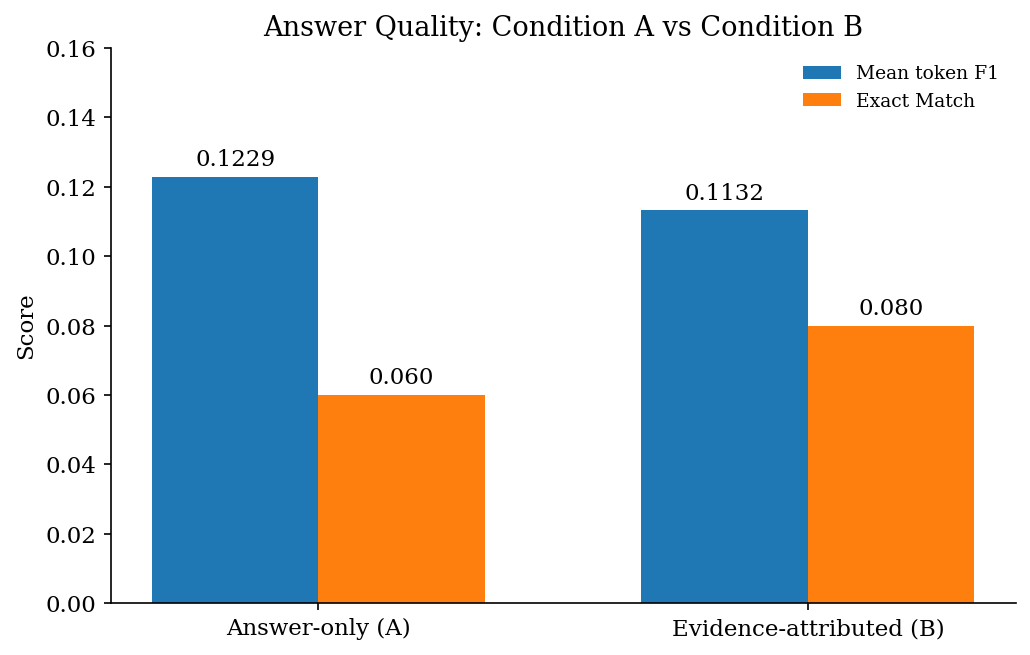

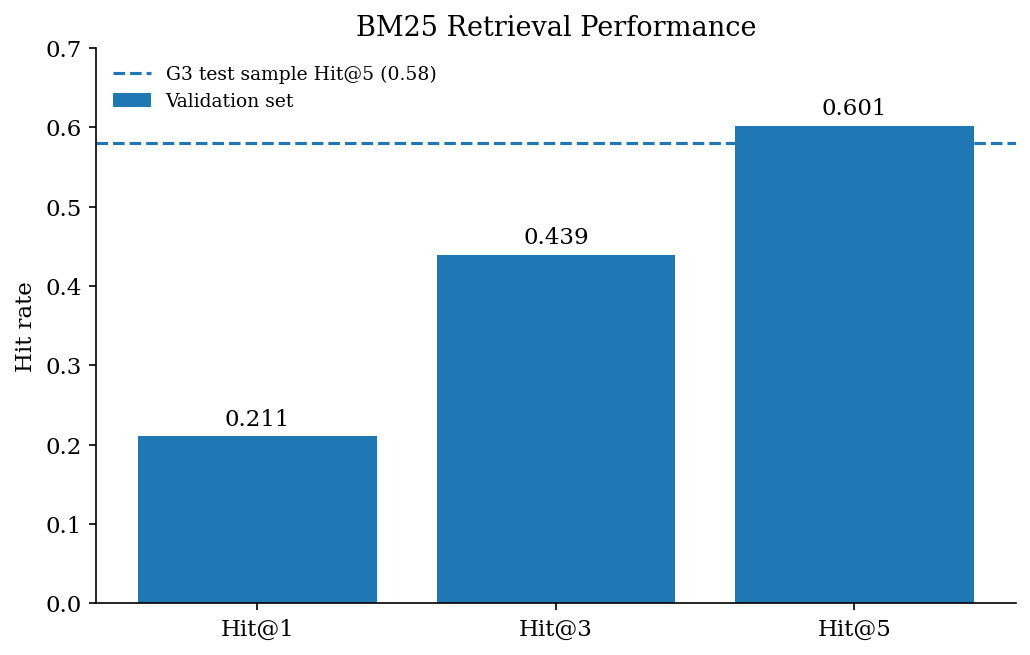

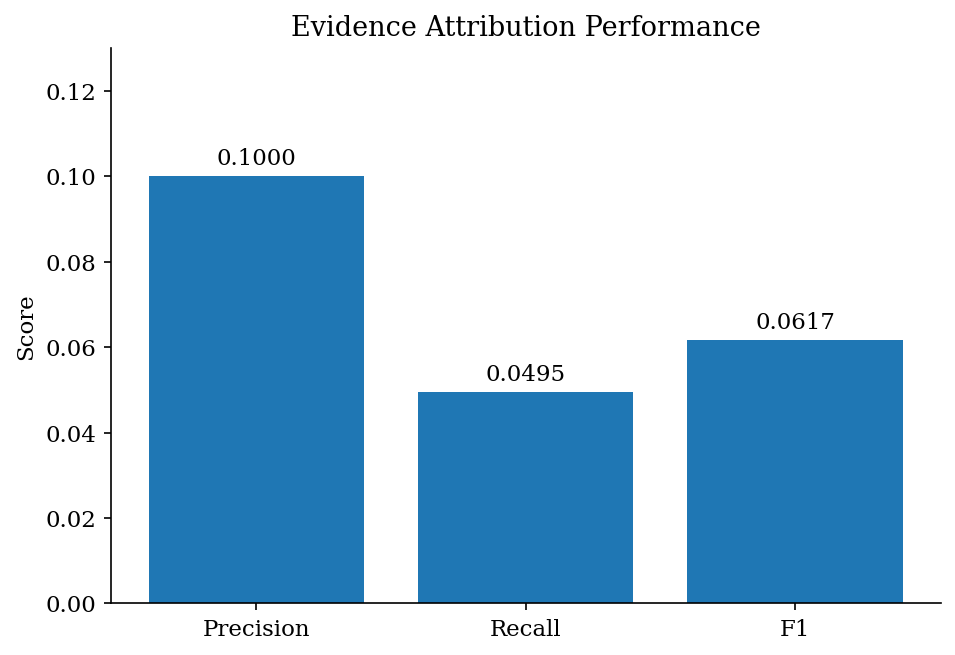

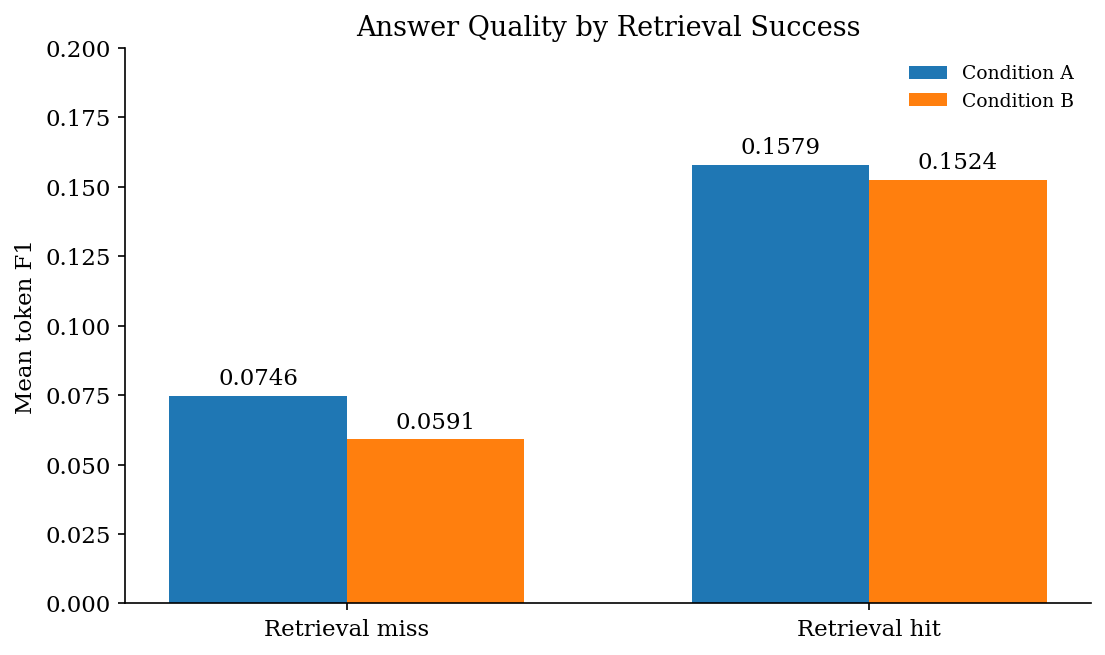

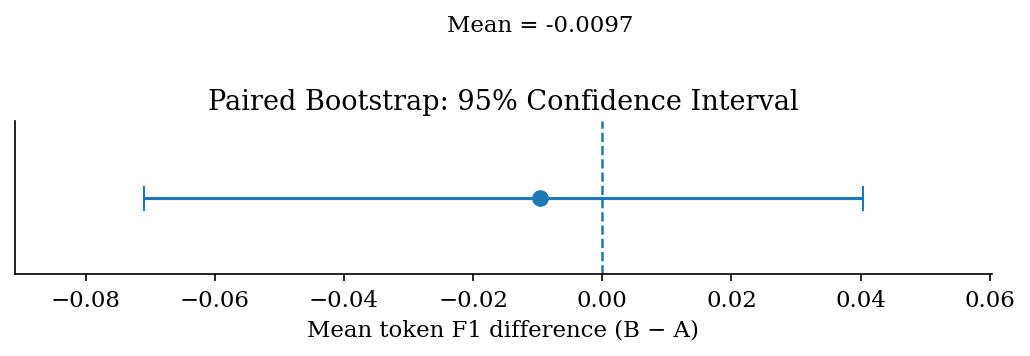


All five research figures generated.
Saved in: g3_research_figures/
ZIP: G3_Research_Figures.zip


In [55]:
# G3.11 — Publication-Quality Visualizations for Research Paper

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create output directory
os.makedirs("g3_research_figures", exist_ok=True)

# Load actual experimental results
df = pd.read_csv("g3_evaluation_results.csv")
summary = pd.read_csv("g3_summary_results.csv")
retrieval = pd.read_csv("g3_retrieval_error_analysis.csv", index_col=0)

# Publication style
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# --------------------------------------------------
# FIGURE 1 — Answer Quality Comparison
# --------------------------------------------------

conditions = ["Answer-only (A)", "Evidence-attributed (B)"]
mean_f1 = [
    df["token_F1_A"].mean(),
    df["token_F1_B"].mean()
]
exact_match = [
    df["exact_match_A"].mean(),
    df["exact_match_B"].mean()
]

fig, ax = plt.subplots(figsize=(7, 4.5))

x = np.arange(2)
width = 0.34

bars1 = ax.bar(
    x - width/2, mean_f1, width,
    label="Mean token F1"
)
bars2 = ax.bar(
    x + width/2, exact_match, width,
    label="Exact Match"
)

ax.set_ylabel("Score")
ax.set_title("Answer Quality: Condition A vs Condition B")
ax.set_xticks(x)
ax.set_xticklabels(conditions)
ax.set_ylim(0, 0.16)
ax.legend(frameon=False)

ax.bar_label(bars1, fmt="%.4f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

fig.tight_layout()
fig.savefig(
    "g3_research_figures/fig1_answer_quality.png",
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# FIGURE 2 — Retrieval Performance
# Validation and test results are clearly separated.
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4.5))

labels = ["Hit@1", "Hit@3", "Hit@5"]
validation_scores = [0.2106, 0.4392, 0.6014]

bars = ax.bar(
    labels, validation_scores,
    label="Validation set"
)

ax.axhline(
    0.58,
    linestyle="--",
    linewidth=1.5,
    label="G3 test sample Hit@5 (0.58)"
)

ax.set_ylabel("Hit rate")
ax.set_title("BM25 Retrieval Performance")
ax.set_ylim(0, 0.7)
ax.legend(frameon=False)

ax.bar_label(bars, fmt="%.3f", padding=3)

fig.tight_layout()
fig.savefig(
    "g3_research_figures/fig2_retrieval_performance.png",
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# FIGURE 3 — Evidence Attribution
# --------------------------------------------------

citation_metrics = [
    df["citation_precision_B"].mean(),
    df["citation_recall_B"].mean(),
    df["citation_F1_B"].mean()
]

citation_labels = [
    "Precision",
    "Recall",
    "F1"
]

fig, ax = plt.subplots(figsize=(6.5, 4.5))

bars = ax.bar(
    citation_labels,
    citation_metrics
)

ax.set_ylabel("Score")
ax.set_title("Evidence Attribution Performance")
ax.set_ylim(0, 0.13)

ax.bar_label(bars, fmt="%.4f", padding=3)

fig.tight_layout()
fig.savefig(
    "g3_research_figures/fig3_evidence_attribution.png",
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# FIGURE 4 — Answer Quality by Retrieval Outcome
# --------------------------------------------------

retrieval_labels = [
    "No gold passage in top 5",
    "Gold passage in top 5"
]

retrieval_values = retrieval.loc[
    [
        "No gold passage in top 5",
        "At least one gold passage in top 5"
    ]
]

fig, ax = plt.subplots(figsize=(7.5, 4.5))

x = np.arange(2)
width = 0.34

bars_a = ax.bar(
    x - width/2,
    retrieval_values["Mean_F1_A"],
    width,
    label="Condition A"
)

bars_b = ax.bar(
    x + width/2,
    retrieval_values["Mean_F1_B"],
    width,
    label="Condition B"
)

ax.set_ylabel("Mean token F1")
ax.set_title("Answer Quality by Retrieval Success")
ax.set_xticks(x)
ax.set_xticklabels(
    ["Retrieval miss", "Retrieval hit"]
)
ax.set_ylim(0, 0.20)
ax.legend(frameon=False)

ax.bar_label(bars_a, fmt="%.4f", padding=3)
ax.bar_label(bars_b, fmt="%.4f", padding=3)

fig.tight_layout()
fig.savefig(
    "g3_research_figures/fig4_retrieval_impact.png",
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# FIGURE 5 — Paired Bootstrap Confidence Interval
# --------------------------------------------------

differences = (
    df["token_F1_B"] - df["token_F1_A"]
).to_numpy()

observed = differences.mean()

rng = np.random.default_rng(42)
bootstrap_means = np.array([
    rng.choice(
        differences,
        size=len(differences),
        replace=True
    ).mean()
    for _ in range(10000)
])

lower, upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

fig, ax = plt.subplots(figsize=(7, 3.5))

ax.errorbar(
    observed,
    0,
    xerr=[[observed - lower], [upper - observed]],
    fmt="o",
    capsize=6,
    markersize=7
)

ax.axvline(0, linestyle="--", linewidth=1.2)

ax.set_yticks([])
ax.set_xlabel("Mean token F1 difference (B − A)")
ax.set_title("Paired Bootstrap: 95% Confidence Interval")
ax.set_xlim(
    min(lower - 0.02, -0.08),
    max(upper + 0.02, 0.05)
)

ax.text(
    observed, 0.12,
    f"Mean = {observed:.4f}",
    ha="center"
)

fig.tight_layout()
fig.savefig(
    "g3_research_figures/fig5_bootstrap_ci.png",
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# PACKAGE ALL FIGURES
# --------------------------------------------------

import zipfile

with zipfile.ZipFile(
    "G3_Research_Figures.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:
    for filename in os.listdir("g3_research_figures"):
        zipf.write(
            os.path.join("g3_research_figures", filename),
            arcname=filename
        )

print("\nAll five research figures generated.")
print("Saved in: g3_research_figures/")
print("ZIP: G3_Research_Figures.zip")